# Trabajo Práctico 3 | Clasificación y evaluación de modelos
**Food Solutions América · Dulce de leche · 2026 · Uso local y confidencial**

**Pregunta:** ¿Puede anticiparse si una elaboración quedará **por debajo del rendimiento esperado** usando los datos de su receta, volumen y composición de leche?

Este notebook sigue la consigna oficial del TP3: marco experimental, tres clasificadores supervisados, modelo de referencia, validación estratificada, análisis de clases, métricas y matrices de confusión para cada modelo, análisis del ajuste, visualizaciones, discusión y conclusiones. Incluye, como **actividades complementarias**, *Random Forest* (ensamble), *K-Means* (agrupamiento) e importancia por permutación.

**Confidencialidad:** no se publica ni se envía a ningún servicio externo. Las 10 elaboraciones de demostración se apartan ANTES de entrenar, validar o probar. Se separan grupos por fecha+lote para evitar que un lote duplicado aparezca en conjuntos distintos.


## 1. Lectura de datos, limpieza y definición de la variable objetivo
La etiqueta se define a partir de los registros históricos: `BAJO_OBJETIVO = 1` cuando `RENDIMIENTO %` es inferior a `RENDIMIENTO ESPERADO`; de lo contrario es `0`.

Variables explicativas (**8**): tipo de masa, litros de leche, azúcar/litro, suero/litro, bicarbonato/litro, L.P.D./litro, materia grasa y proteínas. No utilizamos rendimiento real, rendimiento esperado, kilos obtenidos, identificadores ni información de costos como *features*: algunas columnas pueden introducir información del resultado o no estar disponibles al predecir.


In [1]:
from pathlib import Path
import json, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score,balanced_accuracy_score,precision_score,
 recall_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay,
 roc_curve,roc_auc_score,silhouette_score,ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

SEMILLA = 42
Path('figuras').mkdir(parents=True,exist_ok=True)
RUTA = Path('registro_produccion_LIMPIO.xlsx')
D0 = pd.read_excel(RUTA, sheet_name='Registro Produccion')
D = D0.copy()
columnas_numericas = ['RENDIMIENTO %','RENDIMIENTO ESPERADO','LITROS DE LECHE',
                    'AZUCAR','SUERO','BICARBONATO','L.P.D','MATERIA GRASA','PROTEINAS']
for columna in columnas_numericas:
    D[columna] = pd.to_numeric(D[columna], errors='coerce')
D['FECHA ELABORACION'] = pd.to_datetime(D['FECHA ELABORACION'],errors='coerce')
criterio = (D['RENDIMIENTO %'].notna() & D['RENDIMIENTO ESPERADO'].gt(0)
            & D['LITROS DE LECHE'].gt(0) & D['FECHA ELABORACION'].notna()
            & D['MASA'].notna() & D['Nº LOTE DDL'].notna())
D = D.loc[criterio].copy()
D['BAJO_OBJETIVO'] = (D['RENDIMIENTO %'] < D['RENDIMIENTO ESPERADO']).astype(int)
D['DESVIO_PP']=(D['RENDIMIENTO %']-D['RENDIMIENTO ESPERADO'])*100
for insumo in ['AZUCAR','SUERO','BICARBONATO','L.P.D']:
    D[f'{insumo} por litro']=D[insumo]/D['LITROS DE LECHE']
variables = ['MASA','LITROS DE LECHE','AZUCAR por litro','SUERO por litro',
             'BICARBONATO por litro','L.P.D por litro','MATERIA GRASA','PROTEINAS']
numericas = [v for v in variables if v != 'MASA']
D['GRUPO_LOTE']=(D['FECHA ELABORACION'].dt.strftime('%Y-%m-%d')+'|'
                 +D['Nº LOTE DDL'].astype('str'))
D = D.sort_values(['FECHA ELABORACION','Nº LOTE DDL']).reset_index(drop=True)
print('Filas originales:',len(D0),'| comparables:',len(D),'| descartadas:',len(D0)-len(D))
print('Clases:',D['BAJO_OBJETIVO'].value_counts().sort_index().to_dict())
print('Registros sin contenido de grasa/proteínas:',D[['MATERIA GRASA','PROTEINAS']].isna().sum().to_dict())
print('Cantidad de grupos fecha+lote duplicados:',(D.groupby('GRUPO_LOTE').size()>1).sum())


Filas originales: 1111 | comparables: 1105 | descartadas: 6
Clases: {0: 456, 1: 649}
Registros sin contenido de grasa/proteínas: {'MATERIA GRASA': 25, 'PROTEINAS': 25}
Cantidad de grupos fecha+lote duplicados: 146


## 2. Distribución de clases y protocolo experimental
La distribución incluye más casos por debajo del objetivo. Como **línea base** usamos un clasificador trivial que predice la clase mayoritaria; la regresión logística también representa un algoritmo de referencia del TP3.

**Cambio respecto del notebook anterior:** para cumplir la partición solicitada en el PDF, aquí la división de prueba es **aproximadamente 80/20**, con semilla 42 y estratificación por clase mediante `StratifiedGroupKFold`. El agrupamiento evita que filas de una misma elaboración (fecha+lote) terminen en conjuntos distintos. Para hiperparámetros, se utiliza otra validación cruzada estratificada de 5 pliegues **exclusivamente en entrenamiento**. Las diez elaboraciones de demostración se mantienen totalmente apartadas. Por ello, los resultados de esta versión no deben compararse directamente con el anterior experimento temporal 2025→2026.


,Entrenamiento,Prueba,Reservados
BAJO_OBJETIVO,,,
No por debajo (0),360,91,5
Por debajo (1),515,129,5


Train 875 (79.9%) | Test 220 (20.1%) | Holdout demo 10
Objetivo bajo por masa:


,Elaboraciones,Fracción bajo objetivo
MASA,,
MASA 1,135,0.533333
MASA 2,249,0.538153
MASA 3,246,0.605691
MASA 4,276,0.778986
MASA 5,114,0.614035
MASA 6,24,0.291667
MASA 7,61,0.032787


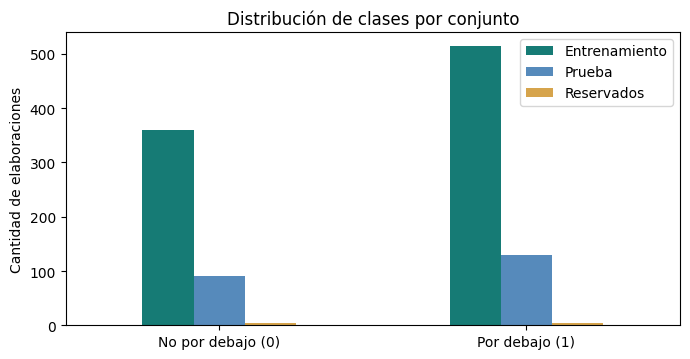

In [2]:
# Reservamos 10 elaboraciones individuales sin filas duplicadas del mismo lote.
D2026 = D[D['FECHA ELABORACION'].dt.year==2026].copy()
tam_grupo = D.groupby('GRUPO_LOTE').size()
singleton = D2026[D2026['GRUPO_LOTE'].map(tam_grupo)==1]
reservados = pd.concat([singleton[singleton['BAJO_OBJETIVO']==0].sample(n=5,random_state=SEMILLA),
                       singleton[singleton['BAJO_OBJETIVO']==1].sample(n=5,random_state=SEMILLA)])
reservados=reservados.sort_values(['FECHA ELABORACION','Nº LOTE DDL']).copy()
restantes = D.loc[~D.index.isin(reservados.index)].copy().reset_index(drop=True)
assert len(reservados)==10 and reservados['GRUPO_LOTE'].nunique()==10
assert not set(reservados['GRUPO_LOTE']) & set(restantes['GRUPO_LOTE'])

sgkf_holdout = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEMILLA)
idx_train, idx_test = next(sgkf_holdout.split(restantes[variables],restantes['BAJO_OBJETIVO'],groups=restantes['GRUPO_LOTE']))
train = restantes.iloc[idx_train].copy()
test = restantes.iloc[idx_test].copy()
assert not set(train['GRUPO_LOTE']) & set(test['GRUPO_LOTE'])
assert len(train)+len(test)+len(reservados)==len(D)

conteo=pd.DataFrame({'Entrenamiento':train['BAJO_OBJETIVO'].value_counts(),
                     'Prueba':test['BAJO_OBJETIVO'].value_counts(),
                     'Reservados':reservados['BAJO_OBJETIVO'].value_counts()}).fillna(0).astype(int)
conteo.index=conteo.index.map({0:'No por debajo (0)',1:'Por debajo (1)'})
display(conteo)
print(f'Train {len(train)} ({len(train)/len(restantes):.1%}) | Test {len(test)} ({len(test)/len(restantes):.1%}) | Holdout demo {len(reservados)}')
print('Objetivo bajo por masa:')
display(D.groupby('MASA')['BAJO_OBJETIVO'].agg(['count','mean']).rename(columns={'count':'Elaboraciones','mean':'Fracción bajo objetivo'}))

fig, ax=plt.subplots(figsize=(7,3.7))
conteo.plot(kind='bar',ax=ax,color=['#167b75','#568abb','#d6a44c'])
ax.set_title('Distribución de clases por conjunto');ax.set_ylabel('Cantidad de elaboraciones');ax.set_xlabel('');ax.tick_params(axis='x',rotation=0)
plt.tight_layout();plt.savefig('figuras/distribucion_clases.png',dpi=150);plt.show()


## 3. Entrenamiento y selección de hiperparámetros
Usamos un `Pipeline`: imputación de datos faltantes y escalado para variables cuantitativas; `OneHotEncoder` para el tipo de masa. Las transformaciones se ajustan **dentro de cada pliegue** y no contaminan la validación.

Los tres algoritmos principales son **regresión logística**, **K vecinos (KNN)** y **árbol de decisión**. Se evalúa, de manera adicional y separada, **Random Forest** como ensamble. Se optimiza `balanced_accuracy` en la validación cruzada y se deja el test intacto hasta que el modelo ya está seleccionado.


In [3]:
def preprocesador():
    return ColumnTransformer([
        ('numericas',Pipeline([
            ('imputador',SimpleImputer(strategy='median')),
            ('estandarizar',StandardScaler())]),numericas),
        ('masa',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['MASA'])
    ])

configuraciones = {
 'Regresión logística': (LogisticRegression(max_iter=3000,random_state=SEMILLA),
                          {'modelo__C':[0.1,1,10],'modelo__class_weight':[None,'balanced']}),
 'K vecinos (KNN)':(KNeighborsClassifier(),
                    {'modelo__n_neighbors':[7,11,15],'modelo__weights':['uniform','distance']}),
 'Árbol de decisión':(DecisionTreeClassifier(random_state=SEMILLA),
                       {'modelo__max_depth':[3,5,7],'modelo__min_samples_leaf':[10,20],
                        'modelo__class_weight':[None,'balanced']}),
 'Random Forest [opcional]':(RandomForestClassifier(n_estimators=100,random_state=SEMILLA,n_jobs=1),
                    {'modelo__max_depth':[5,None],'modelo__min_samples_leaf':[5,10],
                     'modelo__class_weight':['balanced_subsample']})
}

cv = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEMILLA)
busquedas={}
for nombre,(estimador,parametros) in configuraciones.items():
    proceso=Pipeline([('preprocesamiento',preprocesador()),('modelo',estimador)])
    grid=GridSearchCV(proceso,parametros,scoring='balanced_accuracy',cv=cv,n_jobs=1,refit=True)
    grid.fit(train[variables],train['BAJO_OBJETIVO'],groups=train['GRUPO_LOTE'])
    busquedas[nombre]=grid
    print(f'{nombre}: validación = {grid.best_score_:.3f}, parámetros = {grid.best_params_}')

PRINCIPALES=['Regresión logística','K vecinos (KNN)','Árbol de decisión']
ganador=max(PRINCIPALES,key=lambda k:busquedas[k].best_score_)
print('Modelo PRINCIPAL elegido por validación:',ganador)


Regresión logística: validación = 0.631, parámetros = {'modelo__C': 1, 'modelo__class_weight': 'balanced'}


K vecinos (KNN): validación = 0.622, parámetros = {'modelo__n_neighbors': 7, 'modelo__weights': 'uniform'}


Árbol de decisión: validación = 0.651, parámetros = {'modelo__class_weight': 'balanced', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 10}


Random Forest [opcional]: validación = 0.652, parámetros = {'modelo__class_weight': 'balanced_subsample', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 10}
Modelo PRINCIPAL elegido por validación: Árbol de decisión


## 4. Evaluación: métricas y análisis de sobreajuste
Reportamos para cada algoritmo: **Accuracy, Precision, Recall, F1** de la clase 1, **F1 ponderado**, exactitud balanceada y ROC-AUC; también los valores de entrenamiento para ver sobreajuste y test de validación externa. La clase 1 (**elaboración por debajo**) es la positiva, relevante para evitar que un lote problemático pase desapercibido.


In [4]:
def metricas(y, pred, prob):
    return {'Accuracy':accuracy_score(y,pred),
            'Exactitud balanceada':balanced_accuracy_score(y,pred),
            'Precision clase 1':precision_score(y,pred,zero_division=0),
            'Recall clase 1':recall_score(y,pred,zero_division=0),
            'F1 clase 1':f1_score(y,pred,zero_division=0),
            'F1 ponderado':f1_score(y,pred,average='weighted',zero_division=0),
            'ROC-AUC':roc_auc_score(y,prob) if len(np.unique(y))>1 else float('nan')}

resultados=[]; predicciones={}; probas={}
baseline = DummyClassifier(strategy='most_frequent').fit(train[variables],train['BAJO_OBJETIVO'])
for nombre,modelo in [('Baseline mayoría',baseline)]+[(n,x.best_estimator_) for n,x in busquedas.items()]:
    p_train=modelo.predict(train[variables]);p_test=modelo.predict(test[variables])
    if hasattr(modelo,'predict_proba'):
        prob_train=modelo.predict_proba(train[variables])[:,1]
        prob_test=modelo.predict_proba(test[variables])[:,1]
    else:
        prob_train=p_train.astype(float);prob_test=p_test.astype(float)
    met_train=metricas(train['BAJO_OBJETIVO'],p_train,prob_train)
    met_test=metricas(test['BAJO_OBJETIVO'],p_test,prob_test)
    registro={'Modelo':nombre,'CV balanced accuracy':(busquedas[nombre].best_score_ if nombre in busquedas else np.nan),
              'Train bal. acc.':met_train['Exactitud balanceada'],
              'Test bal. acc.':met_test['Exactitud balanceada'],
              'Train accuracy':met_train['Accuracy'],'Test accuracy':met_test['Accuracy'],
              'Precision (1)':met_test['Precision clase 1'],'Recall (1)':met_test['Recall clase 1'],
              'F1 (1)':met_test['F1 clase 1'],'F1 ponderado':met_test['F1 ponderado'],
              'ROC-AUC':met_test['ROC-AUC'],'Brecha train-test':met_train['Exactitud balanceada']-met_test['Exactitud balanceada'],
              'Hiperparámetros':str(busquedas[nombre].best_params_) if nombre in busquedas else 'Clase mayoritaria'}
    resultados.append(registro);predicciones[nombre]=p_test;probas[nombre]=prob_test

comparativa=pd.DataFrame(resultados).set_index('Modelo')
display(comparativa.drop(columns=['Hiperparámetros']).round(3))
print('Hiperparámetros:')
for n,x in busquedas.items():print(n,x.best_params_)

# Informes por clase para los tres modelos y el ensamble.
for nombre in configuraciones:
    print('\nREPORTE:',nombre)
    print(classification_report(test['BAJO_OBJETIVO'],predicciones[nombre],
      labels=[0,1],target_names=['No por debajo','Por debajo'],zero_division=0))
comparativa.to_csv('metricas_TP3.csv',encoding='utf-8-sig')


,CV balanced accuracy,Train bal. acc.,Test bal. acc.,Train accuracy,Test accuracy,Precision (1),Recall (1),F1 (1),F1 ponderado,ROC-AUC,Brecha train-test
Modelo,,,,,,,,,,,
Baseline mayoría,NaN,0.500,0.500,0.589,0.586,0.586,1.000,0.739,0.433,0.500,0.000
Regresión logística,0.631,0.657,0.606,0.672,0.627,0.667,0.729,0.696,0.622,0.661,0.050
K vecinos (KNN),0.622,0.710,0.616,0.730,0.650,0.665,0.814,0.732,0.635,0.635,0.094
Árbol de decisión,0.651,0.660,0.576,0.658,0.577,0.658,0.581,0.617,0.580,0.625,0.084
Random Forest [opcional],0.652,0.713,0.623,0.715,0.632,0.690,0.674,0.682,0.633,0.680,0.090


Hiperparámetros:
Regresión logística {'modelo__C': 1, 'modelo__class_weight': 'balanced'}
K vecinos (KNN) {'modelo__n_neighbors': 7, 'modelo__weights': 'uniform'}
Árbol de decisión {'modelo__class_weight': 'balanced', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 10}
Random Forest [opcional] {'modelo__class_weight': 'balanced_subsample', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 10}

REPORTE: Regresión logística
               precision    recall  f1-score   support

No por debajo       0.56      0.48      0.52        91
   Por debajo       0.67      0.73      0.70       129

     accuracy                           0.63       220
    macro avg       0.61      0.61      0.61       220
 weighted avg       0.62      0.63      0.62       220


REPORTE: K vecinos (KNN)
               precision    recall  f1-score   support

No por debajo       0.61      0.42      0.50        91
   Por debajo       0.66      0.81      0.73       129

     accuracy                           0.

## 5. Matrices de confusión, ROC y gráficos comparativos
En la matriz, una **falsa alarma** es un caso real no bajo (0) que se predijo como bajo (1). Un **falso negativo** es una elaboración realmente por debajo (1) que el algoritmo predijo como no por debajo (0). Una mayor *Recall* de clase 1 ayuda a detectar más elaboraciones problemáticas, pero puede producir más alertas falsas.


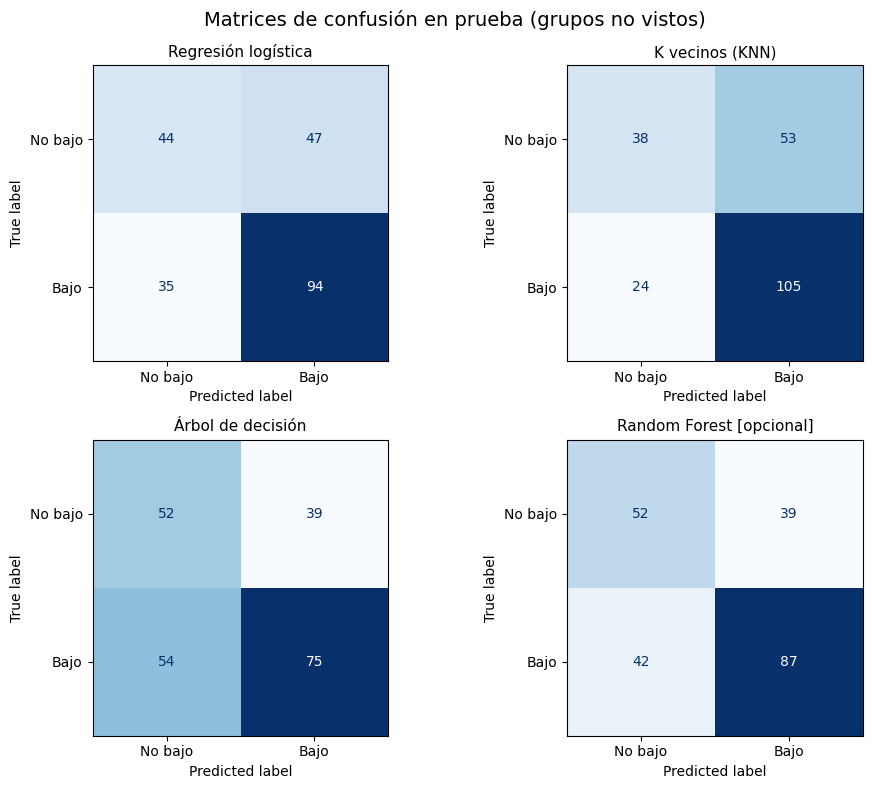

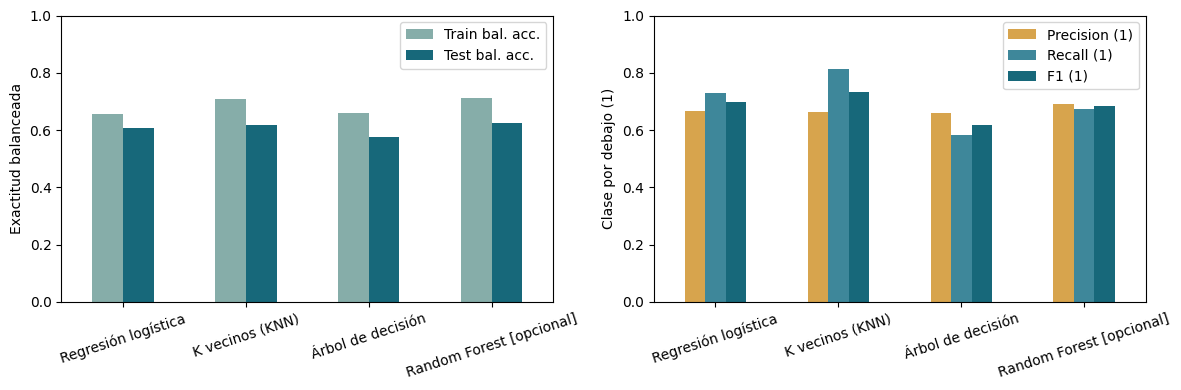

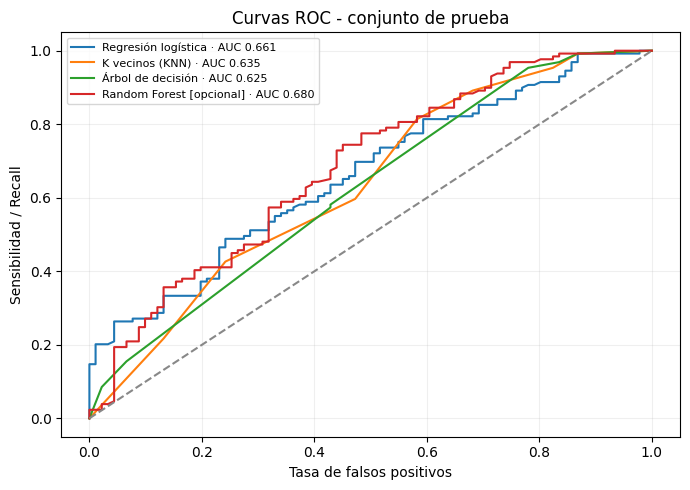

In [5]:
nombres = PRINCIPALES+['Random Forest [opcional]']
fig,axs=plt.subplots(2,2,figsize=(10,8))
for ax,nombre in zip(axs.ravel(),nombres):
    cm=confusion_matrix(test['BAJO_OBJETIVO'],predicciones[nombre],labels=[0,1])
    disp=ConfusionMatrixDisplay(cm,display_labels=['No bajo','Bajo'])
    disp.plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
    ax.set_title(nombre,fontsize=11)
fig.suptitle('Matrices de confusión en prueba (grupos no vistos)',fontsize=14)
plt.tight_layout();plt.savefig('figuras/matrices_confusion.png',dpi=160);plt.show()

fig,axs=plt.subplots(1,2,figsize=(12,4))
comparativa.loc[nombres,['Train bal. acc.','Test bal. acc.']].plot(kind='bar',ax=axs[0],color=['#86ada9','#17687a'])
axs[0].set_ylim(0,1);axs[0].set_ylabel('Exactitud balanceada');axs[0].set_xlabel('');axs[0].tick_params(axis='x',rotation=18)
comparativa.loc[nombres,['Precision (1)','Recall (1)','F1 (1)']].plot(kind='bar',ax=axs[1],color=['#d7a44d','#3e879a','#17687a'])
axs[1].set_ylim(0,1);axs[1].set_ylabel('Clase por debajo (1)');axs[1].set_xlabel('');axs[1].tick_params(axis='x',rotation=18)
plt.tight_layout();plt.savefig('figuras/comparacion_modelos.png',dpi=160);plt.show()

fig,ax=plt.subplots(figsize=(7,5))
for nombre in nombres:
    fpr,tpr,_=roc_curve(test['BAJO_OBJETIVO'],probas[nombre]);auc=roc_auc_score(test['BAJO_OBJETIVO'],probas[nombre])
    ax.plot(fpr,tpr,label=f'{nombre} · AUC {auc:.3f}')
ax.plot([0,1],[0,1],'--',color='#888888');ax.set_xlabel('Tasa de falsos positivos');ax.set_ylabel('Sensibilidad / Recall')
ax.set_title('Curvas ROC - conjunto de prueba');ax.legend(fontsize=8);ax.grid(alpha=.2)
plt.tight_layout();plt.savefig('figuras/curvas_roc.png',dpi=160);plt.show()


## 6. Actividad complementaria: clustering no supervisado con K-Means
Se entrena `K-Means` con las mismas **features** de entrenamiento, sin utilizar las etiquetas. Se escoge *k* por coeficiente de silueta (entre 2 y 6), se muestra la separación con PCA y se comparan los grupos con la categoría real. **Los clusters no son predicciones de bajo rendimiento ni prueban causalidad.**


Silueta por k: {2: 0.59, 3: 0.289, 4: 0.281, 5: 0.233, 6: 0.236}
Mejor k: 2


Clase real,0,1
Cluster,,
0,0.379,0.621
1,1.000,0.000


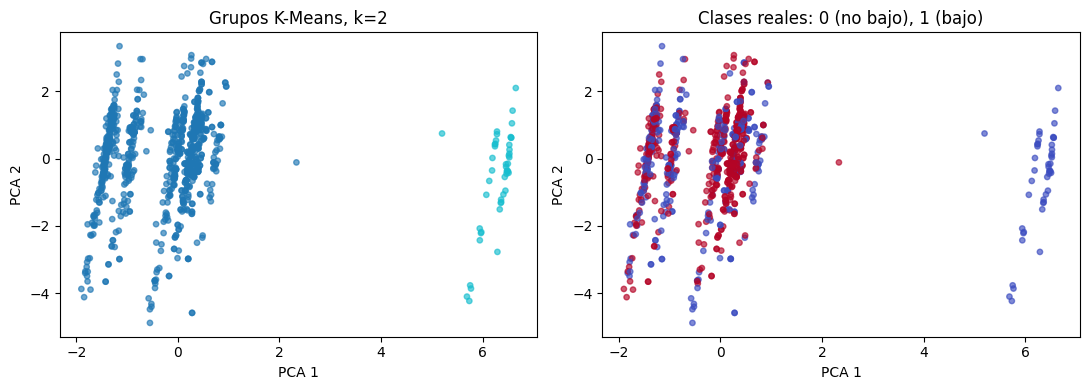

In [6]:
pre_cl=preprocesador().fit(train[variables])
X_cl=pre_cl.transform(train[variables])
puntajes={}
for k in range(2,7):
    km=KMeans(n_clusters=k,random_state=SEMILLA,n_init=10).fit(X_cl)
    puntajes[k]=silhouette_score(X_cl,km.labels_)
k_opt=max(puntajes,key=puntajes.get)
clusterizador=KMeans(n_clusters=k_opt,random_state=SEMILLA,n_init=10).fit(X_cl)
clusters=clusterizador.labels_
res_clusters=pd.crosstab(pd.Series(clusters,name='Cluster'),
                         pd.Series(train['BAJO_OBJETIVO'].to_numpy(),name='Clase real'),normalize='index')
print('Silueta por k:',{k:round(v,3) for k,v in puntajes.items()})
print('Mejor k:',k_opt)
display(res_clusters.round(3))
pca=PCA(n_components=2,random_state=SEMILLA)
X_pca=pca.fit_transform(X_cl)
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].scatter(X_pca[:,0],X_pca[:,1],c=clusters,cmap='tab10',s=15,alpha=.65)
axs[0].set_title(f'Grupos K-Means, k={k_opt}')
axs[1].scatter(X_pca[:,0],X_pca[:,1],c=train['BAJO_OBJETIVO'],cmap='coolwarm',s=15,alpha=.65)
axs[1].set_title('Clases reales: 0 (no bajo), 1 (bajo)')
for ax in axs:
 ax.set_xlabel('PCA 1');ax.set_ylabel('PCA 2')
plt.tight_layout();plt.savefig('figuras/clustering.png',dpi=150);plt.show()


## 7. Interpretabilidad y respuesta crítica a la consigna
Un ranking de importancia por permutación indica qué entradas impactan en el resultado **predictivo** del modelo seleccionado; no identifica causas químicas o físicas. Los falsos negativos son especialmente importantes si no detectar un lote bajo objetivo implica una pérdida o una demora de corrección. No se debe afirmar que los modelos actuales pueden modificar recetas de forma automática.


,Variable,Aumento al permutar,Desvío
4,BICARBONATO por litro,0.066,0.041
3,SUERO por litro,0.020,0.004
7,PROTEINAS,0.004,0.005
0,MASA,0.000,0.000
2,AZUCAR por litro,0.000,0.000
1,LITROS DE LECHE,0.000,0.000
5,L.P.D por litro,0.000,0.000
6,MATERIA GRASA,0.000,0.000


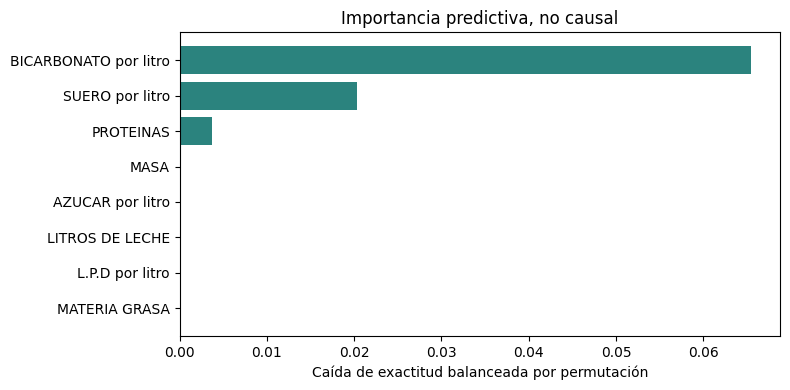

In [7]:
mejor_modelo=busquedas[ganador].best_estimator_
imp=permutation_importance(mejor_modelo,test[variables],test['BAJO_OBJETIVO'],
                           scoring='balanced_accuracy',n_repeats=8,random_state=SEMILLA,n_jobs=1)
importancias=pd.DataFrame({'Variable':variables,'Aumento al permutar':imp.importances_mean,
                           'Desvío':imp.importances_std}).sort_values('Aumento al permutar',ascending=False)
display(importancias.round(3))
fig,ax=plt.subplots(figsize=(8,4))
ax.barh(importancias['Variable'][::-1],importancias['Aumento al permutar'][::-1],color='#2b837e')
ax.axvline(0,color='black',lw=.7);ax.set_xlabel('Caída de exactitud balanceada por permutación')
ax.set_title('Importancia predictiva, no causal')
plt.tight_layout();plt.savefig('figuras/importancia.png',dpi=150);plt.show()


## 8. Serialización y 10 casos reservados para Streamlit local
El modelo elegido se guarda como un único `Pipeline` `.joblib` (modelo + imputación + escalado + codificación). La app no necesita reentrenar ni acceder a todo el Excel. En la demostración: sortear → predecir → revelar el valor real. Nunca usar los casos reservados para elegir hiperparámetros, calibrar el umbral o cambiar de ganador.


In [8]:
joblib.dump(mejor_modelo,'modelo_tp3_final.joblib')
lista_demo=[];reales={}
for n,(_,fila) in enumerate(reservados.iterrows(),start=1):
    ident=f'E{n:02d}'
    entradas={k:(None if pd.isna(v) else str(v) if isinstance(v,str) else float(v))
              for k,v in fila[variables].to_dict().items()}
    lista_demo.append({'id':ident,'fecha':str(fila['FECHA ELABORACION'].date()),
                       'masa':str(fila['MASA']),'lote':str(fila['Nº LOTE DDL']),
                       'entradas':entradas})
    reales[ident]={'BAJO_OBJETIVO':int(fila['BAJO_OBJETIVO']),
                  'rendimiento_real':float(fila['RENDIMIENTO %']),
                  'rendimiento_esperado':float(fila['RENDIMIENTO ESPERADO'])}

Path('datos_demo_10.json').write_text(json.dumps(lista_demo,ensure_ascii=False,indent=2),encoding='utf-8')
Path('verdades_demo_10.json').write_text(json.dumps(reales,ensure_ascii=False,indent=2),encoding='utf-8')
summary = {'titulo':'Clasificación de elaboraciones por debajo del rendimiento esperado',
           'ganador':ganador,'criterio':'Mayor exactitud balanceada en CV estratificada de 5 pliegues',
           'parametros':busquedas[ganador].best_params_,
           'n_inicial':len(D0),'n_comparables':len(D), 'train':len(train), 'test':len(test),
           'reservados':len(reservados),'balance':D['BAJO_OBJETIVO'].value_counts().sort_index().to_dict(),
           'modelos':json.loads(comparativa.drop(columns=['Hiperparámetros']).reset_index().to_json(orient='records')),
           'variables':variables,
           'intervalos':{k:[float(train[k].dropna().min()),float(train[k].dropna().max()),float(train[k].dropna().median())]
                         for k in numericas},
           'cm_ganador':confusion_matrix(test['BAJO_OBJETIVO'],predicciones[ganador],labels=[0,1]).tolist(),
           'importancias':json.loads(importancias.to_json(orient='records')),
           'silhouette':{str(k):round(v,4) for k,v in puntajes.items()},'k':int(k_opt)}
Path('resumen_tp3.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')

# Verificación estricta de que el modelo guardado reproduce la salida.
cargado=joblib.load('modelo_tp3_final.joblib')
assert np.array_equal(cargado.predict(test[variables]),mejor_modelo.predict(test[variables]))
assert not set(reservados['GRUPO_LOTE'])&set(train['GRUPO_LOTE'])
assert not set(reservados['GRUPO_LOTE'])&set(test['GRUPO_LOTE'])
print('Modelo serializado y verificado. Diez casos completamente apartados.')
print('Casos demo:',[(r['id'],r['fecha'],r['masa']) for r in lista_demo])


Modelo serializado y verificado. Diez casos completamente apartados.
Casos demo: [('E01', '2026-02-11', 'MASA 7'), ('E02', '2026-02-20', 'MASA 2'), ('E03', '2026-03-13', 'MASA 1'), ('E04', '2026-03-16', 'MASA 6'), ('E05', '2026-03-26', 'MASA 1'), ('E06', '2026-04-13', 'MASA 3'), ('E07', '2026-05-16', 'MASA 2'), ('E08', '2026-06-29', 'MASA 5'), ('E09', '2026-07-10', 'MASA 2'), ('E10', '2026-07-30', 'MASA 3')]


## 9. Conclusiones, cuestionario del TP3 y limitaciones
**A. ¿Qué modelo fue el más adecuado?** El elegido por validación cruzada estratificada (no por mirar el test): se reportan sus hiperparámetros y todas las métricas. Si se priorizara *recall* de la clase 1 en lugar de exactitud balanceada, la elección podría cambiar. El análisis de matriz de confusión cuantifica las falsas alarmas (FP) y los bajos rendimientos no detectados (FN).

**B. ¿Hubo sobreajuste o subajuste?** Comparar explícitamente entrenamiento y prueba de cada clasificador. Una brecha grande y positiva sugiere sobreajuste; rendimientos bajos en ambos sugieren dificultad estructural o subajuste. `class_weight='balanced'` es un ajuste considerado en la búsqueda, sin re-muestrear el test.

**C. ¿Por qué difieren los algoritmos?** Las recetas, la materia prima y los tipos de masa producen relaciones complejas. El dataset carece de variables operativas clave como tiempo y temperatura de cocción. Los grupos *K-Means* describen similitudes pero no equivalen a etiquetas de bajo rendimiento. *Random Forest* puede mejorar la estabilidad a costa de complejidad; solo las métricas de la tabla permiten comprobarlo.

**Conclusión:** los modelos permiten explorar asociaciones predictivas, pero no demuestran causalidad ni justifican ajustes automáticos en planta. En el TP4 puede reutilizarse el `Pipeline` serializado desde una app privada.
